# Day 5(M1 Day05) 보충 실습 — 팀 시험 하네스: 개선 전후를 숫자로 (자율 구현)

**목표**: 본 실습 2-2는 기준 12점과 14점을 **한 번씩** 돌려 비교했다. 한 번의 결과는 운일 수 있다. 과제 여러 개를 버전마다 **세 번씩** 풀게 해서, 게이트·재시도 구조를 바꾼 효과를 네 가지 지표로 잰다.
> 🧭 **이 노트북은 코드를 직접 다 짓는 버전이다.** 코드 셀에는 `# TODO` 지시사항만 있다. 지시를 읽고 처음부터 구현한다.
>
> - 함수 이름·인자·반환 모양은 **지시대로** 맞춘다. 뒤 셀과 확인 셀이 그 이름을 그대로 쓴다.
> - `✅ 확인` 셀은 고치지 않는다. 실행해서 `통과`가 나오면 다음으로 넘어간다.
> - 막히면 `Day05-보충-팀시험하네스-실습.ipynb`(빈칸 채우기 버전)를 힌트로 보고, 다 끝나면 `-정답.ipynb`와 비교한다.

## 오늘의 전체 그림

**오늘의 질문**: 게이트·재시도 구조를 바꾼 효과가 운이 아니라는 것을 어떻게 숫자로 보이나?

```text
[Part 1 문제지]   시험 과제 4개 TASKS · 채점 함수 check(코드)
      ▼
[Part 2 시험 대상] 세 버전 run_version: v1 단일 · v2 새로 다시 쓰기 · v3 지적된 곳만 고치기
      ▼
[Part 3 반복]     버전 3 × 과제 4 × 3회 → records → 지표표 (완료율 · 1차 통과율 · 일관성 · 작성 횟수)
      ▼
[Part 4 보고]     실패한 최종본 보기 · 채점 기준 v2로 모든 버전 다시 채점 · 보고서
```

| Part | 답하는 질문 | 다음 Part로 넘기는 것 |
| --- | --- | --- |
| Part 1 | 무엇으로, 무엇을 채점하나? | `TASKS` · `check` |
| Part 2 | 비교할 게이트·재시도 구조는? | `write` · `run_version` |
| Part 3 | 반복하면 버전 차이가 남나? | `records` · 지표표 |
| Part 4 | 숫자 뒤의 실패는 무엇이고, 채점이 틀렸다면? | 보고서 → M2 Day 8 CI의 회귀 시험 |

> 💡 네 Part는 코드를 이어 쓴다. Part 3의 `records`가 Part 4의 재료다.

| 지표 | 한 줄 정의 |
| --- | --- |
| 완료율 | 최종본이 채점을 통과한 비율 |
| 1차 통과율 | 첫 초안이 그대로 통과한 비율 — 게이트 없이도 됐을 비율 |
| 응답 일관성 | 같은 과제를 3번 풀었을 때 결과(통과/실패)가 3번 모두 같은 과제의 비율 |
| 평균 작성 횟수 | 최종본까지 작성자를 부른 횟수의 평균 — 비용 |

**선수**: 본 실습 Part 1(게이트·피드백 루프), 확장 실습(웹 조사 리서치 팀)의 "지적된 곳만 고치기".

> 💡 **시험 하네스란**: 시험 대상을 끼워 넣으면 같은 문제지·같은 채점·같은 반복 횟수로 돌려 결과를 비교표로 모아 주는 틀이다 (문제지 → 채점 함수 → 반복 실행 → 버전 비교표). 대상만 바꿔 끼우고 틀은 그대로 둔다 → 결과 차이가 대상에서만 나온다. 오늘 끼워 넣는 대상은 **게이트·재시도 구조**(v1·v2·v3)다. 2과목 Day 17에서 LangSmith로 실행 **한 번**을 추적해 봤다면, 오늘은 실행 **여러 번**을 숫자로 비교한다.

> ⚠️ 이 노트북은 LLM을 60~100번 부른다 (gpt-4o-mini, 짧은 글이라 비용은 적다). Part 3이 3~5분 걸린다.

## 0. 환경 준비

In [ ]:
import os

# 추적 끄기: 2과목 Day17에서 .env의 LANGSMITH_TRACING을 켰다면 오늘 호출이 전부 전송된다
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

import pandas as pd
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.9)  # 작성자: 본 실습과 같은 설정 → 실행마다 결과가 흔들린다
print("준비 완료:", llm.model_name)

## Part 1. 문제지와 채점

**전체 그림 1/4**: 시험 과제와 채점 함수를 만든다 → 모든 버전을 이 문제지·채점으로 잰다.

### 1-1. 시험 과제 4개

본 실습의 달빛 도서관에 과제 3개를 더한다. 과제마다 **반드시 인용할 수치**(`required`)가 3개다. 본 실습에서는 2개였다 → 빠뜨리기 쉽게 조금 어렵게 했다.

> 💡 쉬운 과제만 넣으면 모든 버전이 100%가 나와 비교가 안 된다.

In [ ]:
TASKS = [
    {
        "name": "달빛 도서관",
        "source": "달빛 도서관은 밤 10시부터 새벽 2시까지 여는 무인 야간 도서관이다. 서울 마포구에 1호점이 있고 좌석은 48석이다. "
        "월 구독료는 19,900원이다. 안내 로봇 '루나'가 책 추천과 반납을 돕는다. 회원의 62%가 20~30대 직장인이다. "
        "2026년 12월 부산 2호점을 연다.",
        "required": ["19,900원", "62%", "48석"],
    },
    {
        "name": "솔방울 캠핑 카페",
        "source": "솔방울은 경기 가평의 숲속 캠핑 카페다. 텐트 12동을 시간 단위로 빌려 준다. 2시간 이용료는 15,000원이다. "
        "장작과 음료가 포함된다. 방문객의 70%가 가족 단위다. 반려견 동반 구역이 따로 있다. 2027년 봄 강원 2호점을 연다.",
        "required": ["15,000원", "70%", "12동"],
    },
    {
        "name": "보송 세탁 라운지",
        "source": "보송은 서울 성수동의 무인 세탁 라운지다. 세탁기 20대와 건조기 16대가 있다. 세탁 1회 요금은 4,500원이다. "
        "기다리는 동안 쓸 수 있는 작업 책상이 있다. 이용자의 55%가 1인 가구다. 앱으로 남은 시간을 알려 준다.",
        "required": ["4,500원", "55%", "20대"],
    },
    {
        "name": "첨벙 반려견 수영장",
        "source": "첨벙은 경기 용인의 반려견 전용 실내 수영장이다. 수영장 3개를 크기별로 나눴다. 1시간 이용료는 25,000원이다. "
        "수의사가 매일 수질을 점검한다. 재방문율은 81%다. 주말 예약은 2주 전에 마감된다.",
        "required": ["25,000원", "81%", "3개"],
    },
]


### 1-2. 채점 함수 — 코드로 판정

본 실습의 스타일 검사기와 같다. 과제마다 필수 수치가 다를 뿐이다. 채점을 LLM에 맡기지 않는다 → 몇 번을 돌려도 같은 글에는 같은 점수가 나온다.

In [ ]:
REQUEST = "잠재 투자자에게 보낼 소개 글. 서비스 개요·고객·수익 모델을 담을 것. 4~6문장."
BANNED = ["혁신", "최고", "완벽", "획기적", "세계적", "압도적"]
print(len(TASKS), "개 과제")

In [ ]:
# TODO: 채점 함수 check(draft, task)를 만드세요. LLM을 쓰지 않고 코드로만 판정합니다.
#   - 입력: draft(작성자가 쓴 글, 문자열), task(TASKS의 원소 하나)
#   - 반환: 위반 목록(list[str]). 빈 목록이면 통과
#   - 규칙 1: BANNED의 단어가 글에 있으면  과장 표현 "단어"  를 추가 (BANNED 순서대로)
#   - 규칙 2: task["required"]의 수치가 글에 없으면  필수 수치 "수치" 누락  을 추가 (required 순서대로)
#   - 규칙 1의 위반을 먼저, 규칙 2의 위반을 나중에 담습니다

In [ ]:
# ✅ 확인 (고치지 않는다)
got = check("혁신적인 도서관. 구독료 19,900원.", TASKS[0])
print(got)
assert got == ['과장 표현 "혁신"', '필수 수치 "62%" 누락', '필수 수치 "48석" 누락'], "규칙·순서·문구를 지시와 비교하세요"
assert check("구독료 19,900원, 회원 62%, 좌석 48석.", TASKS[0]) == [], "위반이 없으면 빈 목록이어야 합니다"
print("통과")

## Part 2. 시험 대상 — 세 버전

**전체 그림 2/4**: Part 1의 `check`를 게이트로 쓰는 세 버전을 만든다 → Part 3이 같은 조건으로 반복 실행한다.

| 버전 | 구조 | 재시도 때 작성자가 받는 것 |
| --- | --- | --- |
| v1 | 작성자 혼자 (Day 1의 단일 에이전트) | — (재시도 없음) |
| v2 | 작성자 → 게이트 → (미달 시) 작성자, 최대 3번 | 위반 목록 → **처음부터 새로** 쓴다 |
| v3 | v2와 같다 | 위반 목록 + **이전 초안** → 지적된 곳만 고친다 |

게이트는 1-2의 `check()`다 (코드 검사만). 본 실습의 루브릭 검증자는 뺐다 → 버전 차이가 **구조 차이**에서만 나오게 한다.

> ⚠️ v1~v3에서 LLM 에이전트는 **작성자 하나**뿐이고, 게이트는 코드 함수다. 그래서 이 비교는 에이전트 여럿의 협업이 아니라 **에이전트 하나 + 코드 검사기의 피드백 루프**를 비교하는 것이다. 게이트를 LLM 검증자 에이전트로 바꾼 v4(멀티에이전트)는 마지막 확장 미션에서 같은 하네스로 시험한다.

**함수 흐름 (시퀀스)** — 실선 화살표는 호출, 점선 화살표는 반환이다. v1은 첫 초안에서 끝나고, v2·v3는 위반이 없어질 때까지 최대 3번 쓴다. v2와 v3의 차이는 다시 쓸 때 **이전 초안**을 넘기느냐뿐이다.

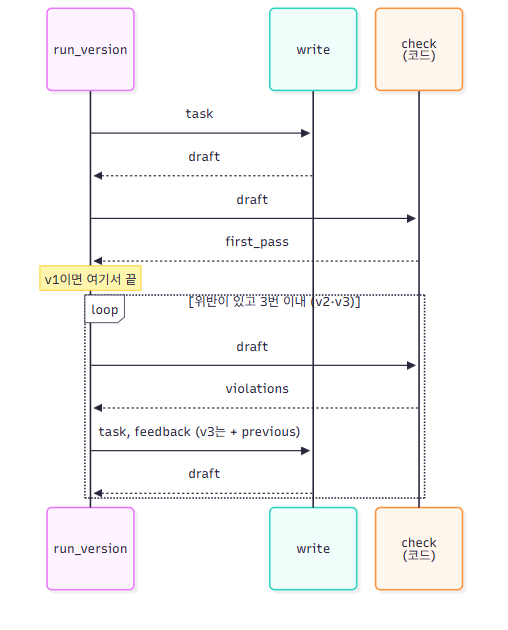

<details>
<summary>mermaid 원본 (그림을 고칠 때 쓴다)</summary>

```mermaid
%%{init: {"sequence": {"actorMargin": 24, "width": 110, "noteMargin": 6, "boxMargin": 6}}}%%
sequenceDiagram
    participant R as run_version
    participant W as write
    participant C as check<br/>(코드)
    R->>W: task
    W-->>R: draft
    R->>C: draft
    C-->>R: first_pass
    Note over R: v1이면 여기서 끝
    loop 위반이 있고 3번 이내 (v2·v3)
        R->>C: draft
        C-->>R: violations
        R->>W: task, feedback (v3는 + previous)
        W-->>R: draft
    end
```

</details>

In [ ]:
# TODO: 작성자 함수 write(task, feedback="", previous="")를 만드세요. llm을 1번 부르고 글(문자열)을 돌려줍니다.
#   - 기본 프롬프트: 작성자 역할 + "원문의 사실만 사용, 글만 출력" 지시 + [요청] REQUEST + [원문] task["source"]
#   - feedback도 previous도 없으면: 기본 프롬프트만으로 새로 씁니다 (첫 초안)
#   - feedback만 있으면 (v2): 기본 프롬프트 뒤에 게이트의 지적을 붙이고 "반드시 모두 반영"하라고 합니다 → 처음부터 새로 쓴다
#   - feedback과 previous가 모두 있으면 (v3): [이전 초안]과 [게이트의 지적]을 붙이고
#     "지적된 곳만 고치고 나머지는 그대로 두라"고 합니다
#   - 응답은 .content의 앞뒤 공백을 지워서 돌려줍니다
#
# 다 만들었으면 아래처럼 한 번 불러 글이 나오는지 봅니다.
# print(write(TASKS[1]))

In [ ]:
# TODO: run_version(version, task)를 만드세요. 한 과제를 한 버전으로 한 번 풉니다.
#   - 먼저 작성 상한 상수 MAX_WRITES = 3 을 정의합니다 (확인 셀이 이 이름을 씁니다)
#   - 첫 초안을 write(task)로 쓰고, 그 초안이 check를 통과했는지를 first_pass에 기록합니다
#   - v1: 첫 초안으로 끝납니다 (재시도 없음)
#   - v2·v3: 위반이 있는 동안 다시 씁니다. 첫 초안을 포함해 최대 MAX_WRITES번까지만 씁니다
#       · 피드백은 위반 목록을 "- 위반" 한 줄씩 이어 붙인 문자열
#       · v2는 write(task, feedback)       → 새로 쓰기
#       · v3는 write(task, feedback, previous=직전 초안) → 지적된 곳만 고치기
#   - 반환: {"draft": 최종본, "writes": 작성자를 부른 횟수, "first_pass": 첫 초안 통과 여부}

In [ ]:
# ✅ 확인 (고치지 않는다) — LLM을 2~4번 부른다
r1 = run_version("v1", TASKS[0])
r3 = run_version("v3", TASKS[0])
assert set(r1) == {"draft", "writes", "first_pass"}, "반환 딕셔너리의 키를 지시와 맞추세요"
assert r1["writes"] == 1, "v1은 한 번만 씁니다"
assert 1 <= r3["writes"] <= MAX_WRITES, "작성 횟수가 상한을 넘었습니다"
assert not (r3["first_pass"] and r3["writes"] > 1), "첫 초안이 통과했으면 다시 쓰지 않습니다"
print("v3 작성", r3["writes"], "회 | 1차 통과", r3["first_pass"], "| 최종 위반", check(r3["draft"], TASKS[0]))
print("통과")

## Part 3. 반복 실행과 지표표

**전체 그림 3/4**: 세 버전을 과제마다 세 번씩 풀게 해 `records`를 쌓고 지표표를 낸다 → Part 4가 숫자 뒤의 실패를 본다.

### 3-1. 세 번씩 풀기

버전 3개 × 과제 4개 × 3번 = 36번 푼다. 결과를 한 줄씩 `records`에 쌓는다.

In [ ]:
# TODO: 세 버전을 과제마다 REPEAT번씩 풀어 records(list[dict])에 한 줄씩 쌓으세요.
#   - VERSIONS = ["v1", "v2", "v3"], REPEAT = 3 으로 둡니다 → 3 × 4 × 3 = 36줄
#   - 한 줄에 담을 키 (뒤 셀들이 이 이름을 씁니다):
#       version     버전 이름
#       task        과제 이름 (task["name"])
#       trial       회차 1~REPEAT
#       passed      최종본이 check를 통과했는가 (bool)
#       first_pass  run_version이 돌려준 1차 통과 여부
#       writes      작성 횟수
#       violations  최종본의 위반 목록을 ", "로 이은 문자열
#       draft       최종본 글
#   - 버전 하나가 끝날 때마다 진행 상황을 출력하면 기다리기 편합니다 (3~5분 걸린다)

In [ ]:
# ✅ 확인 (고치지 않는다)
assert len(records) == len(VERSIONS) * len(TASKS) * REPEAT, "기록 수가 버전 × 과제 × 반복 수와 다릅니다"
assert set(records[0]) == {"version", "task", "trial", "passed", "first_pass", "writes", "violations", "draft"}, "키 이름을 지시와 맞추세요"
print(len(records), "건 기록 — 통과")

### 3-2. 지표표

`groupby`는 **같은 값끼리 묶어 평균을 낸다** (Day 1과 같다). `passed`는 True/False라 평균이 곧 비율이다.

In [ ]:
# TODO: records를 DataFrame(df)으로 바꾸고, 버전별 지표표 table을 만드세요.
#   - version으로 묶어 passed · first_pass · writes의 평균을 내고 소수 둘째 자리로 반올림합니다
#   - 열 이름은 "완료율", "1차 통과율", "평균 작성 횟수"
#   - 마지막 줄에 table을 두어 표가 보이게 합니다

In [ ]:
# TODO: consistency(version)를 만들고, 버전마다 응답 일관성을 출력하세요.
#   - 과제마다 그 버전의 passed 결과 REPEAT개를 모읍니다
#   - 결과가 모두 같으면(모두 통과 또는 모두 실패) 그 과제는 "일관됨"
#   - 반환: "일관된 과제 수/과제 수" 형태의 문자열 (예: "3/4")
#   - Part 4에서 다시 채점한 뒤에도 이 함수를 그대로 다시 씁니다 → records를 읽어서 계산하세요

**관찰 포인트** — 내 실행 결과로 답한다

- 게이트가 있는 v2·v3와 게이트가 없는 v1의 완료율은 얼마나 달랐나? 그 대가로 평균 작성 횟수는 얼마나 늘었나?
- 세 버전 모두 첫 초안은 **같은 방법**으로 쓴다. 그런데 1차 통과율이 버전마다 다르게 나왔다면, 그 차이는 무엇 때문인가?
- v2와 v3의 차이가 보였나? 이 한 번의 결과로 "지적된 곳만 고치기가 낫다(또는 못하다)"고 결론 내려도 되나?
- 응답 일관성이 가장 낮은 버전은? 게이트는 품질 말고 무엇을 바꾸나?

## Part 4. 실패 사례와 보고

**전체 그림 4/4**: Part 3의 `records`에서 실패 사례를 꺼내 보고, 채점 기준이 틀렸을 때 다시 채점해 보고서에 옮긴다.

### 4-1. 실패한 최종본 보기

숫자만 보면 **왜** 실패했는지 모른다. 실패한 것을 골라 위반 내용과 글을 직접 읽는다.

In [ ]:
# TODO: 최종본이 실패한 기록만 골라 fails에 담고, 실패 건수와 앞 6건을 출력하세요.
#   - 한 건마다: [버전 · 과제 · 회차] 위반 내용  을 한 줄, 그 아래에 글 앞 200자

In [ ]:
# TODO: 과제별 표 by_task를 만드세요. 어느 과제가 어려웠는지 봅니다.
#   - task로 묶어 passed · first_pass의 평균, 소수 둘째 자리
#   - 열 이름은 "완료율", "1차 통과율"

**관찰 포인트** — 내 실행 결과로 답한다

- 실패는 어느 버전에 몰렸나?
- 실패한 글을 직접 읽고 위반을 두 종류로 나눈다.
  1. 글이 정말 수치를 빠뜨렸다
  2. 뜻은 맞는데 **표현이 채점 문자열과 달라서** 떨어졌다 (예: 원문 "12동", 글 "12개의 텐트")
- 과제별 표에서 1차 통과율이 가장 낮은 과제는? 과제가 어려워서인가, 채점 기준이 좁아서인가?

2번에 해당하는 실패를 메모해 둔다. 4-3에서 채점 기준을 고칠 근거가 된다.

### 4-3. 채점 기준이 틀렸다면 — 모든 버전을 다시 채점

4-1의 실패 글을 읽어 보면, 글이 틀린 것이 아니라 **채점 기준이 좁아서** 떨어진 것이 있을 수 있다. 예: 원문은 "텐트 12동"인데 "12개의 텐트"라고 쓰면 뜻은 맞아도 `"12동"` 문자열이 없다.

채점 기준을 고칠 때 지킬 것 두 가지.

| 규칙 | 이유 |
| --- | --- |
| 무엇을 왜 바꿨는지 `CHANGES`에 적는다 | 기록이 없으면 읽는 사람이 수치를 믿을 수 없다 |
| **모든 버전**을 새 기준으로 다시 채점한다 | 한 버전만 다시 채점하면 비교가 공정하지 않다 |

LLM을 다시 부르지 않는다. `records`에 저장해 둔 최종본을 새 기준으로 다시 채점할 뿐이다.

In [ ]:
# TODO: 채점 기준 v2를 만드세요.
#   1) has(draft, word): word를 "|"로 나눈 표현 중 하나라도 draft에 있으면 True
#      (예: has("12개의 텐트", "12동|12개") → True)
#   2) check_v2(draft, task): check와 같지만, 필수 수치를 비교할 때 `in` 대신 has를 씁니다
#      위반 문구와 순서는 check와 같습니다

In [ ]:
# ✅ 확인 (고치지 않는다)
assert has("12개의 텐트", "12동|12개") is True
assert has("텐트 여러 동", "12동|12개") is False
assert check_v2("텐트 12개, 2시간 15,000원, 가족 70%", {"required": ["15,000원", "70%", "12동|12개"]}) == []
assert check_v2("혁신적인 카페", {"required": ["70%"]}) == ['과장 표현 "혁신"', '필수 수치 "70%" 누락']
print("통과")

In [ ]:
# TODO: 4-1에서 메모한 "표현이 달라 떨어진" 실패를 근거로 채점 기준을 고치고, 모든 버전을 다시 채점하세요.
#   1) CHANGES(list[str])에 무엇을 왜 바꿨는지 한 줄씩 적습니다
#      형식 예: "과제 이름의 필수 수치 '원래' → '원래|허용 표현' (떨어진 글의 실제 표현)"
#   2) 해당 과제의 TASKS[...]["required"]를 "|"로 넓힙니다 — 내 실패 사례에 실제로 나온 표현만 허용합니다
#   3) records의 모든 기록(모든 버전)의 passed를 check_v2로 다시 채점합니다. LLM은 다시 부르지 않습니다
#      (records에는 과제 이름만 있으니, 이름으로 과제를 찾는 딕셔너리를 만들면 편합니다)
#   4) df를 다시 만들고 버전별 표 table2를 냅니다. 열 이름은 "완료율", "1차 통과율(기준 v1)", "평균 작성 횟수"
#      → 1차 통과율은 다시 채점할 수 없습니다. 왜 그런지는 관찰 포인트에서 답합니다
#   5) CHANGES와 버전별 응답 일관성(consistency)을 출력하고, 마지막 줄에 table2를 둡니다

**관찰 포인트** — 내 실행 결과로 답한다

- 기준을 고친 뒤 v1의 완료율은 얼마나 바뀌었나? 에이전트는 그대로인데 왜 수치가 바뀌었나?
- 3-2의 표만 보고 "게이트가 완료율을 얼마 올렸다"고 보고했다면, 효과를 몇 배 부풀린 것인가?
- 1차 통과율은 왜 다시 채점하지 못했나? 무엇을 `records`에 저장해 뒀어야 했나?
- 허용 표현을 계속 넓히면 무엇이 문제인가? 어디까지 같은 뜻으로 볼지는 누가 정해야 하나?

### 4-2. 보고서에 옮기기

| 보고서에 적을 것 | 이 노트북에서 가져올 것 |
| --- | --- |
| 시험 조건 | 과제 4개 × 3번, 작성자 temperature 0.9, 게이트 = 코드 검사, 최대 작성 3번 |
| 버전별 무엇을 바꿨나 | Part 2 표 |
| 네 지표 | 3-2 지표표 + 응답 일관성 |
| 실패 사례와 원인 | 4-1 출력 — 위반 종류와 과제 |
| 결론 | "무엇을 바꿨더니 어느 지표가 얼마나 변했다" 한 줄 |

> 💡 결론에는 **비용**도 함께 적는다. 완료율이 올라도 평균 작성 횟수가 두 배면, 그 값을 치를 만한지 판단하는 것은 서비스를 운영하는 사람이다.

## 확장 미션 — v4: 게이트를 LLM 검증자 에이전트로 바꾸면?

v1~v3에서 LLM 에이전트는 작성자 하나였고 게이트는 코드(`check`)였다. 본 실습의 루브릭 검증자처럼 **게이트도 LLM 에이전트**로 바꾸면, 작성자와 검증자 두 에이전트가 일하는 멀티에이전트 구조가 된다. 같은 하네스에 v4를 끼워 넣어 v2와 비교한다.

| 버전 | 게이트 | 재시도 때 작성자가 받는 것 | LLM 에이전트 |
| --- | --- | --- | --- |
| v2 | 코드 `check` | 위반 목록 | 작성자 |
| v4 | 검증자 (루브릭 합계 12점 이상이면 통과) | 검증자의 피드백 | 작성자 + 검증자 |

**최종 채점은 바꾸지 않는다.** v4의 최종본도 v1~v3와 같은 코드 채점(4-3의 `check_v2`)으로 잰다 → 틀은 그대로 두고 끼워 넣는 대상만 바꾼다.

> ⚠️ 4-3까지 실행한 뒤에 한다 (`df`, `check_v2`, 고친 `TASKS`를 쓴다). LLM을 25~40번 부른다.

In [ ]:
# TODO: 검증자 에이전트와 v4를 만드세요.
#   1) llm_strict = gpt-4o-mini, temperature 0 (검증자는 흔들리면 안 된다)  /  PASS_SCORE = 12 (본 실습 2-2의 기준)
#   2) Evaluation 계약(pydantic BaseModel): faithfulness · completeness · clarity (각 1~5 정수), feedback (문자열)
#      필드 description에 감점 기준을 적습니다:
#        faithfulness  원문에 없는 내용·수치 왜곡이 하나라도 있으면 3 이하
#        completeness  개요·고객·수익 모델 중 하나라도 빠지거나 원문의 핵심 수치(요금·비율·규모)를 인용하지 않으면 3 이하
#        clarity       문장이 늘어지거나 반복되거나 과장 표현이 있으면 감점
#        feedback      점수를 올리기 위한 구체적 개선 지시 2~3개, 한국어
#   3) evaluate(task, draft): 검증자 역할 + "5점은 결점이 전혀 없을 때만" + [요청] REQUEST · [원문] · [초안]으로
#      llm_strict에 Evaluation 계약을 걸어 채점시킵니다
#   4) run_v4(task): 첫 초안 → 검증 → 세 점수 합이 PASS_SCORE 이상이면 통과
#      미달이면 write(task, ev.feedback)로 새로 쓰고 다시 검증. 첫 초안을 포함해 최대 MAX_WRITES번 씁니다
#      반환: {"draft": 최종본, "writes": 작성 횟수, "evals": 검증자 호출 횟수, "judge_pass": 마지막 검증의 통과 여부}

In [ ]:
# ✅ 확인 (고치지 않는다) — LLM을 2~6번 부른다
r = run_v4(TASKS[0])
assert set(r) == {"draft", "writes", "evals", "judge_pass"}, "반환 딕셔너리의 키를 지시와 맞추세요"
assert 1 <= r["writes"] <= MAX_WRITES, "작성 횟수가 상한을 넘었습니다"
assert r["evals"] == r["writes"], "초안마다 검증자를 한 번씩 불러야 합니다"
print("작성", r["writes"], "회 | 검증자 통과", r["judge_pass"], "| 코드 채점 위반", check_v2(r["draft"], TASKS[0]))
print("통과")

In [ ]:
# TODO: v4를 과제마다 REPEAT번씩 풀어 v4_records에 한 줄씩 쌓으세요.
#   - 최종본은 v1~v3와 같은 코드 채점(check_v2)으로 채점합니다 → 하네스의 채점은 바꾸지 않는다
#   - 한 줄에 담을 키: version("v4"), task, trial, passed(코드 채점 통과), judge_pass(검증자 통과),
#                     writes, evals, violations(", "로 이은 문자열), draft

In [ ]:
# TODO: v2와 v4를 비교하는 표 compare를 만들고, 검증자와 코드 채점이 어긋난 건수를 출력하세요.
#   1) 4-3에서 다시 채점한 df의 v2 기록과 v4_records를 합칩니다 (v2에는 evals가 없으니 0으로 채웁니다)
#   2) LLM 호출 수 = writes + evals
#   3) version별 평균: 완료율(코드 채점) · 평균 작성 횟수 · 평균 LLM 호출 수
#   4) "검증자는 통과, 코드 채점은 실패" 건수와 그 위반 내용 몇 개, "검증자는 미달, 코드 채점은 통과" 건수를 출력합니다
#   5) 마지막 줄에 compare를 둡니다

**관찰 포인트** — 내 실행 결과로 답한다

- 검증자는 몇 건을 첫 초안에서 통과시켰나? v4의 평균 작성 횟수는?
- 검증자는 통과시켰는데 코드 채점에서 떨어진 글이 있었나? 검증자가 무엇을 놓쳤나?
- v2와 v4의 완료율·평균 LLM 호출 수를 비교한다. 에이전트를 하나 더 넣은 값을 했나?
- 필수 수치·금지어 판정은 코드와 LLM 검증자 중 누구에게 맡겨야 하나? LLM 검증자는 무엇을 판정할 때 써야 하나?

## 확인 문제

**1. 한 번만 돌려서 비교하면 안 되는 이유는?**



**2. 채점을 LLM이 아니라 코드(`check`)로 한 이유는?**



**3. 1차 통과율은 버전마다 비슷한데 완료율은 다르다면 무엇을 뜻하나?**



**4. 응답 일관성이 높으면 좋은 버전인가?**


**5. 평균 작성 횟수를 지표에 넣는 이유는?**



## 정리·회고

1. 오늘 시험에서 v2와 v3의 차이는 작성자 프롬프트 몇 줄이었다. 그 몇 줄의 효과를 무엇으로 증명했는가?
2. 본 실습 캡스톤(분석가 4명 + 통합자 + 루브릭 검증자)을 이 하네스로 시험하려면 무엇을 바꿔야 하는가? (비용·채점 방법)